# R02R: state-space control from the linearized model

`CR02R_control_theory.ipynb` worked from the outside in: it ran a step test,
fitted a transfer function $G(s)$, and designed in the frequency domain.
This notebook works from the inside out. It takes PharmaPy's own model of
R02R (the jacketed CSTR with three parallel reactions), linearizes it at its
steady state, and designs on the state vector itself:

1. **Operating point**: find the steady state $f(x_0, u_0, d_0) = 0$.
2. **LTI model**: $\dot x = A x + B u + E d,\; y = C x$ by linearizing
   PharmaPy's right-hand side, and a check against the nonlinear model.
3. **Modes and stability**: eigenvalues, time constants, and which states
   each mode moves.
4. **Controllability and observability**: Kalman rank, the PBH test,
   Gramians, and why a single input cannot reach most of the composition.
5. **Model reduction**: Hankel singular values, balanced truncation, and the
   transfer function the state space implies.
6. **State feedback**: pole placement, then LQR with integral action (LQI).
7. **State estimation**: a Kalman filter on the temperature alone, what it
   can and cannot recover, and how an unmeasured disturbance biases it.
8. **LQG**: the two together; the separation principle, and robustness.
9. **Nonlinear validation**: the LQG controller running *inside* PharmaPy on
   the nonlinear model, with and without a disturbance estimate, against
   PharmaPy's own PI jacket loop.

**The LTI assumption.** Every result below holds for small deviations from
the steady state, where $f$ is well approximated by its Jacobian. Section 2
measures how small "small" is for R02R; section 9 runs the designs on the
full nonlinear model to see whether the assumption held.

**Signals.**

| | Symbol | What | At the operating point |
|---|---|---|---|
| input | $u$ | jacket (coolant) inlet temperature | 60 °C |
| disturbance | $d$ | feed temperature | 30 °C |
| output | $y$ | vessel temperature (measured) | ≈ 64.4 °C |

PharmaPy's PI level loop holds the volume throughout, so it is part of the
plant. The state is PharmaPy's own solver state: the liquid mass of each of
the 12 database species, the temperature, and the level loop's integral.

In [1]:
# The PharmaPy runs are cached by R02R_state_space.py (about 20 s):
#   python R02R_state_space.py
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import linalg, signal

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import R02R_state_space as ss

DATA = ss.OUT_DIR
np.set_printoptions(precision=4, suppress=False, linewidth=110)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e5e4e0",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "legend.frameon": False})
INK, MUTED = "#0b0b0b", "#52514e"
C_LQG, C_PI, C_LIN = "#2a78d6", "#eb6834", "#0b0b0b"
SPECIES_COLORS = {"A": "#2a78d6", "D": "#eb6834", "E": "#1baf7a", "F": "#eda100",
                  "G": "#8a5cd1", "H": "#5f6b7a", "I": "#d6457a", "J": "#14a3b8"}


def uniform(t, *ys, dt=ss.DT_SAVE):
    # Saved histories can hold event points and repeated times: resample.
    t = np.asarray(t, dtype=float)
    keep = np.r_[True, np.diff(t) > 1e-9]
    grid = np.arange(t[0], t[keep][-1] + 1e-9, dt)
    out = [np.interp(grid, t[keep], np.asarray(y, dtype=float)[keep]) for y in ys]
    return (grid, *out)

## 1. Operating point

R02R is run for 10 h (about 7 residence times) from its charge of pure
solvent with the jacket at 60 °C and the feed at 30 °C. The end of that run
is close to steady, but "close" is not good enough for a linearization: if
$f(x_0) \neq 0$, the "LTI model" has a constant forcing term and the
operating point drifts. So the end of the run is polished with Newton's
method on PharmaPy's own right-hand side, $x \leftarrow x - J^{-1} f(x)$,
until $f(x_0)$ is zero to round-off.

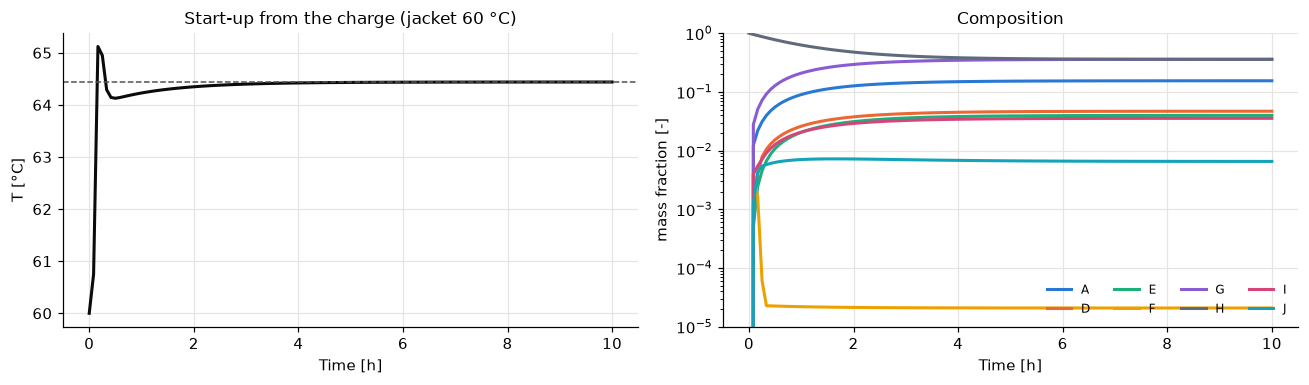

Newton on f(x) = 0:  |f| = 4.3e-06  ->  2.6e-11  ->  2.0e-16

Operating point x0  (T0 = 337.5897 K = 64.44 °C)
  m_A       13.89 kg   w = 0.1545
  m_B           0 kg   w = 0
  m_C           0 kg   w = 0
  m_D       4.206 kg   w = 0.0468
  m_E       3.571 kg   w = 0.03974
  m_F    0.001867 kg   w = 2.078e-05
  m_G       32.19 kg   w = 0.3582
  m_H       32.24 kg   w = 0.3588
  m_I       3.183 kg   w = 0.03541
  m_J      0.5863 kg   w = 0.006524
  m_K           0 kg   w = 0
  m_L           0 kg   w = 0
  level_integral -0.001558 m3 s


In [2]:
st = np.load(DATA / "steady_state.npz")
model = ss.load_model()
names, labels = model.names, model.labels
n_sp = len(names)
x0 = model.x0

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(st["time"] / 3600, st["temp"] - 273.15, color=INK, lw=2)
ax[0].axhline(x0[model.i_temp] - 273.15, color=MUTED, ls="--", lw=1)
ax[0].set(xlabel="Time [h]", ylabel="T [°C]", title="Start-up from the charge (jacket 60 °C)")
mass = st["mass"]
for j, s in enumerate(names):
    if s in SPECIES_COLORS:
        ax[1].plot(st["time"] / 3600, mass[:, j] / mass.sum(axis=1), color=SPECIES_COLORS[s],
                   lw=2, label=s)
ax[1].set(xlabel="Time [h]", ylabel="mass fraction [-]", yscale="log", ylim=(1e-5, 1),
          title="Composition")
ax[1].legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

print("Newton on f(x) = 0:  |f| =", "  ->  ".join(f"{v:.1e}" for v in st["newton"]))
print(f"\nOperating point x0  (T0 = {x0[model.i_temp]:.4f} K = {x0[model.i_temp]-273.15:.2f} °C)")
w0 = x0[:n_sp] / x0[:n_sp].sum()
for j, s in enumerate(names):
    print(f"  m_{s:<2} {x0[j]:10.4g} kg   w = {w0[j]:.4g}")
print(f"  level_integral {x0[-1]:.4g} m3 s")

Newton converges in two steps, quadratically, as it should when the run has
already brought the state close. The remaining $|f|$ is round-off, so the
linearization below has no constant term: it is a genuine LTI model about an
equilibrium.

B, C, K and L have zero mass: nothing feeds or makes them. They stay in the
state vector because PharmaPy carries every database species.

## 2. The linear time-invariant model

Write the deviations from the operating point as
$\delta x = x - x_0$, $\delta u = u - u_0$, $\delta d = d - d_0$. Expanding
$f$ to first order,

$$\dot{\delta x} = \underbrace{\frac{\partial f}{\partial x}\Big|_0}_{A}\,\delta x
+ \underbrace{\frac{\partial f}{\partial u}\Big|_0}_{B}\,\delta u
+ \underbrace{\frac{\partial f}{\partial d}\Big|_0}_{E}\,\delta d,
\qquad \delta y = C\,\delta x .$$

$A$, $B$ and $E$ are computed by central differences of
`MultiPhaseVessel.unit_model`, the function CVode integrates, so the linear
model is PharmaPy's model and not a re-derivation. $C$ picks out the
temperature. The matrices are constant (time-invariant) because $u_0$ and
$d_0$ are held constant and nothing in R02R depends on time explicitly.

The mass fractions are outputs too, through a second, linearized map:
$w_j = m_j/M$, so $\delta w_j = (\delta m_j - w_j\,\delta M)/M$.

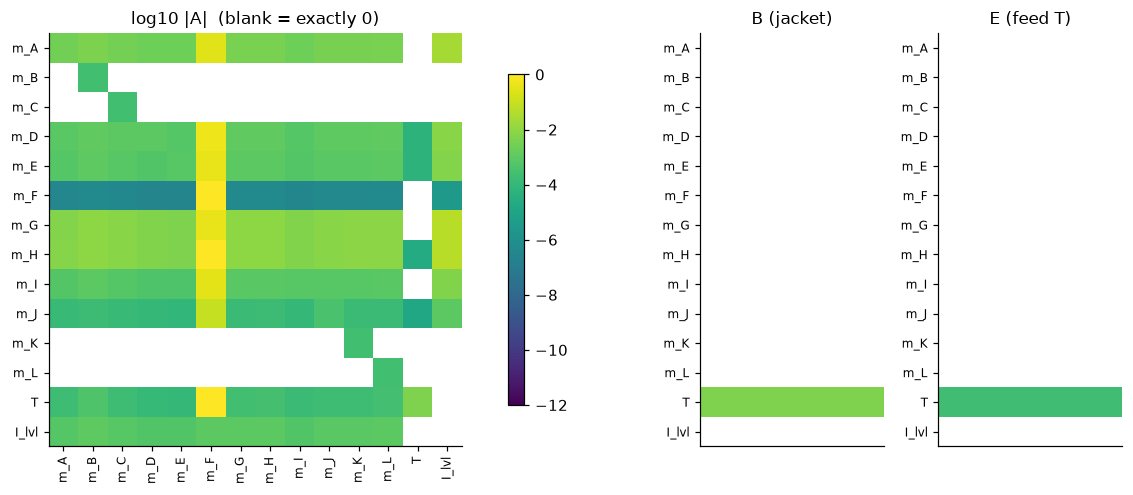

B nonzero: {'T': '4.785e-03'}
E nonzero: {'T': '2.165e-04'}
Steady-state gain  dT/du = 0.9508345252478323   dT/dd = 0.04301991384580345


In [3]:
A, B, E, C = model.A, model.B, model.E, model.C
n = A.shape[0]
short = [l.replace("global_temp", "T").replace("level_integral", "I_lvl") for l in labels]

fig, ax = plt.subplots(1, 3, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[5, 1, 1]))
mag = np.log10(np.abs(A) + 1e-300)
im = ax[0].imshow(np.where(np.abs(A) > 0, mag, np.nan), cmap="viridis", vmin=-12, vmax=0)
ax[0].set_xticks(range(n), short, rotation=90, fontsize=8)
ax[0].set_yticks(range(n), short, fontsize=8)
ax[0].set_title("log10 |A|  (blank = exactly 0)")
ax[0].grid(False)
plt.colorbar(im, ax=ax[0], shrink=0.8)
for a, M, t in ((ax[1], B, "B (jacket)"), (ax[2], E, "E (feed T)")):
    a.imshow(np.where(np.abs(M) > 0, np.log10(np.abs(M) + 1e-300), np.nan), cmap="viridis",
             vmin=-12, vmax=0, aspect="auto")
    a.set_xticks([]); a.set_yticks(range(n), short, fontsize=8); a.set_title(t); a.grid(False)
plt.tight_layout(); plt.show()

print("B nonzero:", {short[i]: f"{B[i,0]:.3e}" for i in np.nonzero(B[:, 0])[0]})
print("E nonzero:", {short[i]: f"{E[i,0]:.3e}" for i in np.nonzero(E[:, 0])[0]})
print("Steady-state gain  dT/du =", (-C @ np.linalg.solve(A, B)).item(),
      "  dT/dd =", (-C @ np.linalg.solve(A, E)).item())

**Reading the structure.**
- $B$ and $E$ each have a single nonzero entry, in the temperature row: the
  jacket and the feed temperature act only through the energy balance.
  Everything the jacket does to the composition goes through $T$, via the
  Arrhenius terms in the $T$ column of $A$.
- The rate laws depend on A, F and G only, so only those columns reach the
  other species rows. The product masses (D, E, J), H and I feed back into
  nothing but their own wash-out and the total mass.
- The steady-state gain $dT/du \approx 0.95$: a little under 1, because the
  feed and the reaction also set $T$. $dT/dd$ is small (≈ 0.04): the feed is
  only 0.02 kg/s into an 80 kg vessel.

**How good is the LTI assumption?** The cached nonlinear run starts at
$x_0$, steps the jacket by +2 K at 0.25 h, then the feed temperature by
+20 K at 3 h. The same inputs go through the linear model.

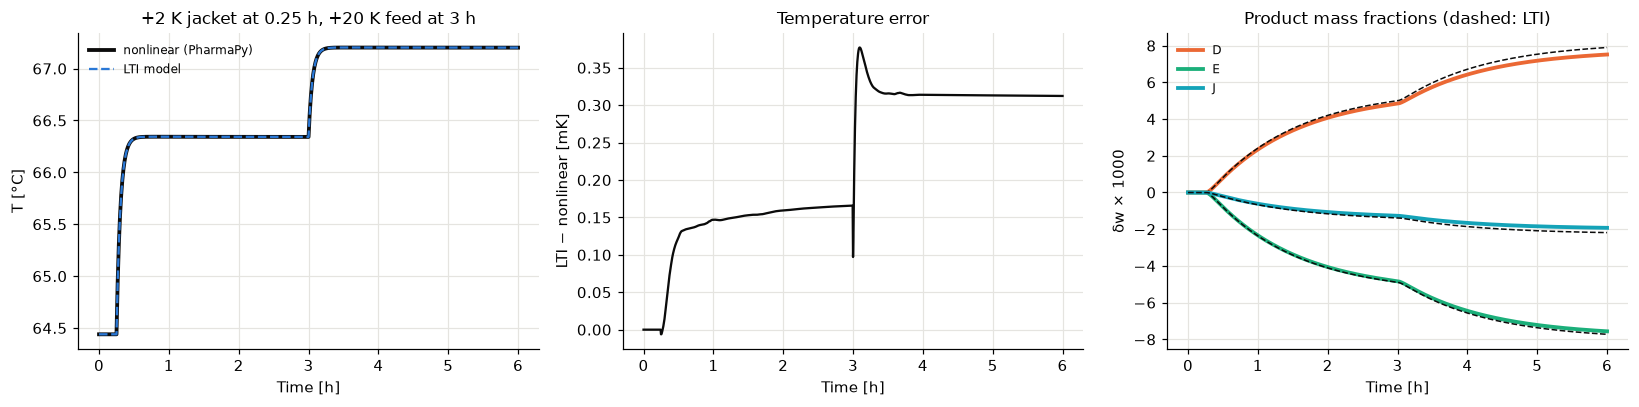

jacket +2 K  T moves 1.904 K; worst LTI error 0.2 mK (0.0% of the move)
feed +20 K   T moves 0.861 K; worst LTI error 0.4 mK (0.0% of the move)


In [4]:
ol = np.load(DATA / "open_loop.npz")
t, T_nl, u_nl, d_nl = uniform(ol["time"], ol["temp"], ol["u"], ol["d"])
U = np.column_stack([u_nl - model.u0, d_nl - model.d0])
sys_full = signal.StateSpace(A, np.hstack([B, E]), np.vstack([C, model.Cw]), np.zeros((1 + n_sp, 2)))
_, Y, _ = signal.lsim(sys_full, U, t, interp=False)
T_lin = x0[model.i_temp] + Y[:, 0]

frac_nl = np.column_stack([np.interp(t, *uniform(ol["time"], ol["frac"][:, j])) for j in range(n_sp)])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(t / 3600, T_nl - 273.15, color=INK, lw=2.5, label="nonlinear (PharmaPy)")
ax[0].plot(t / 3600, T_lin - 273.15, color=C_LQG, lw=1.5, ls="--", label="LTI model")
ax[0].set(xlabel="Time [h]", ylabel="T [°C]", title="+2 K jacket at 0.25 h, +20 K feed at 3 h")
ax[0].legend(fontsize=8)
ax[1].plot(t / 3600, (T_lin - T_nl) * 1e3, color=INK, lw=1.5)
ax[1].set(xlabel="Time [h]", ylabel="LTI − nonlinear [mK]", title="Temperature error")
for s in ("D", "E", "J"):
    j = names.index(s)
    ax[2].plot(t / 3600, (frac_nl[:, j] - w0[j]) * 1e3, color=SPECIES_COLORS[s], lw=2.5, label=f"{s}")
    ax[2].plot(t / 3600, Y[:, 1 + j] * 1e3, color=INK, lw=1, ls="--")
ax[2].set(xlabel="Time [h]", ylabel="δw × 1000", title="Product mass fractions (dashed: LTI)")
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

i_d = np.searchsorted(t, ss.OPEN_T_D)
for lab, sl, step in (("jacket +2 K", slice(0, i_d), ss.OPEN_DU), ("feed +20 K", slice(i_d, None), None)):
    err = np.abs(T_lin[sl] - T_nl[sl]).max()
    move = np.ptp(T_nl[sl])
    print(f"{lab:<12} T moves {move:.3f} K; worst LTI error {err*1e3:.1f} mK ({err/move:.1%} of the move)")

The LTI model tracks the nonlinear temperature to 0.2 mK on the 1.9 K
jacket response and 0.4 mK after the feed step, about 0.02 % of the move.
What error there is, is a small mismatch in steady-state gain: the
nonlinear gain at the new point differs slightly from the slope at $x_0$.
The compositions are less linear. D, E and J follow the right trends (D up,
E and J down with temperature, as the activation energies say: D's is the
only positive one), but by 6 h the LTI model overstates the change in D by
a few percent, as the composition drifts on the residence-time scale
(≈ 75 min) and carries the plant away from the point the Jacobian was taken
at.

(These runs use explicit CVode tolerances, `rtol` 1e-8 and `atol` 1e-10. On
Assimulo's defaults the same comparison showed ~1.5 mK, nearly all of it
integration error, and R02R ran ~35× slower.)

## 3. Modes and stability

For $\dot{\delta x} = A\,\delta x$, the solution is a sum of modes
$v_i e^{\lambda_i t}$. The system is **asymptotically stable** if and only if
every eigenvalue has $\mathrm{Re}\,\lambda_i < 0$.

Which states a mode involves is read from its eigenvector. The masses (kg)
and the temperature (K) differ in size, so each state is first divided by
how far it moves for a 1 K jacket step (`ss.scaling`); the participation
factor $p_{ki} = |w_{ik} v_{ki}|$ (left and right eigenvectors) then says
how much state $k$ takes part in mode $i$.

Full model (14 states): max Re(lambda) = -2.234e-04 1/s  ->  STABLE
Absent species ['m_B', 'm_C', 'm_K', 'm_L'] each give lambda = -2.2358e-04 (wash-out only) and are dropped below.

            lambda [1/s]   tau [s]   main participants
 -2.2336e-04+0.0e+00j    4477.1   m_J 0.32, m_A 0.23, m_G 0.17
 -2.2358e-04+0.0e+00j    4472.6   m_J 0.38, m_D 0.35, m_G 0.12
 -2.2358e-04+8.9e-14j    4472.6   m_D 0.22, m_E 0.22, m_I 0.21
 -2.2358e-04-8.9e-14j    4472.6   m_D 0.22, m_E 0.22, m_I 0.21
 -2.2358e-04+0.0e+00j    4472.6   m_D 0.66, m_E 0.12, m_J 0.09
 -2.2391e-04+0.0e+00j    4466.2   m_D 0.38, m_E 0.34, m_J 0.19
 -5.0228e-03+0.0e+00j     199.1   T 1.00, I_lvl 0.00, m_H 0.00
 -1.1310e-02+5.4e-05j      88.4   I_lvl 0.50, m_H 0.20, m_G 0.20
 -1.1310e-02-5.4e-05j      88.4   I_lvl 0.50, m_H 0.20, m_G 0.20
 -1.0002e+00+0.0e+00j       1.0   m_F 1.00, m_H 0.00, m_G 0.00


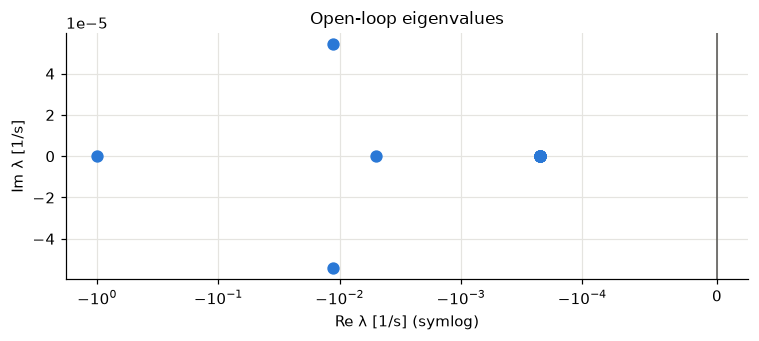

In [5]:
red = ss.reduced(model)
s_ = ss.scaling(red)
As = np.diag(1 / s_) @ red.A @ np.diag(s_)
Bs, Es, Cs = red.B / s_[:, None], red.E / s_[:, None], red.C * s_[None, :]
rlab = [short[i] for i in model.keep]

lam_full = np.linalg.eigvals(A)
lam, W, V = linalg.eig(As, left=True)
order = np.argsort(-lam.real)
lam, W, V = lam[order], W[:, order], V[:, order]
P = np.abs(W.conj() * V)
P /= P.sum(axis=0, keepdims=True)

print(f"Full model ({n} states): max Re(lambda) = {lam_full.real.max():.3e} 1/s  ->  "
      f"{'STABLE' if lam_full.real.max() < 0 else 'UNSTABLE'}")
print(f"Absent species {[short[i] for i in model.absent]} each give lambda = "
      f"{np.diag(A)[model.absent][0]:.4e} (wash-out only) and are dropped below.\n")
print(f"{'lambda [1/s]':>24} {'tau [s]':>9}   main participants")
for i in range(len(lam)):
    top = np.argsort(-P[:, i])[:3]
    who = ", ".join(f"{rlab[k]} {P[k, i]:.2f}" for k in top)
    print(f"{lam[i].real:>12.4e}{lam[i].imag:+.1e}j {-1/lam[i].real:9.1f}   {who}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.scatter(lam_full.real, lam_full.imag, s=50, color=C_LQG, zorder=3)
ax.set_xscale("symlog", linthresh=1e-4); ax.axvline(0, color=MUTED, lw=1)
ax.set(xlabel="Re λ [1/s] (symlog)", ylabel="Im λ [1/s]", title="Open-loop eigenvalues")
plt.tight_layout(); plt.show()

**R02R is open-loop stable** at this operating point: every eigenvalue is in
the left half-plane. The participation factors name four time scales:

- **≈ 1 s: F.** F is the scarce reactant (fed at about a tenth of A and G)
  and nearly all of it reacts on arrival. Its 1.9 g inventory turns over in
  about a second, the stiffest mode in the model.
- **≈ 88 s, a near-double pair: the level loop.** PharmaPy's PI level
  controller is part of the plant, and its default $T_i = 4/K_c$ puts a
  critically damped double pole at $-K_c/2$, with $1/K_c$ a hundredth of a
  residence time. It moves the total mass (H and G, the big inventories).
- **≈ 199 s: the temperature**, participation 1.00. It is close to
  $m c_p/(UA)$ = 209 s (the value PharmaPy's PI loop reads as $T_i$), sped
  up a little by the feed and the reaction heat. CR02R's was 201 s.
- **≈ 4470 s: the residence time** $	au = M/F_{in}$. Six modes sit here
  (ten in the full model, counting the four absent species). They belong to
  combinations of the masses that feed back into nothing (D, E, H, I, J
  enter no rate law), so each simply washes out.

That cluster of equal eigenvalues has consequences for controllability.

## 4. Controllability and observability

**Controllability**: can $u$ steer the state from any $\delta x$ to any other
in finite time? **Observability**: can the full $\delta x$ be reconstructed
from $y(t)$? Three standard tests, all in the scaled coordinates:

1. **Kalman rank**: $\mathcal{C} = [B, AB, \dots, A^{n-1}B]$ and
   $\mathcal{O} = [C; CA; \dots; CA^{n-1}]$ must have rank $n$. Numerically,
   look at the singular values.
2. **PBH (Popov–Belevitch–Hautus)**: mode $\lambda_i$ is uncontrollable iff
   $w_i^* B = 0$ for its left eigenvector, unobservable iff $C v_i = 0$.
   Equivalently $[\lambda I - A,\; B]$ loses rank. The PBH test has a sharp
   corollary: **with one input, an eigenvalue with two or more independent
   eigenvectors is always uncontrollable**, since $B$ is a single column and
   cannot excite two independent directions at once.
3. **Gramians**: $W_c = \int_0^\infty e^{At}BB^Te^{A^Tt}dt$ and
   $W_o = \int_0^\infty e^{A^Tt}C^TCe^{At}dt$, from the Lyapunov equations
   $AW_c + W_cA^T + BB^T = 0$ and $A^TW_o + W_oA + C^TC = 0$. These grade
   *how* controllable or observable a direction is, not just whether it is.

In [6]:
nr = As.shape[0]
Ctrb = np.hstack([np.linalg.matrix_power(As, k) @ Bs for k in range(nr)])
Obsv = np.vstack([Cs @ np.linalg.matrix_power(As, k) for k in range(nr)])
sc = np.linalg.svd(Ctrb, compute_uv=False); so = np.linalg.svd(Obsv, compute_uv=False)
tol = 1e-8
print(f"Kalman controllability matrix: singular values / largest\n  {sc / sc[0]}")
print(f"  numerical rank (tol {tol:g}): {np.sum(sc / sc[0] > tol)} of {nr}")
print(f"Kalman observability matrix: singular values / largest\n  {so / so[0]}")
print(f"  numerical rank (tol {tol:g}): {np.sum(so / so[0] > tol)} of {nr}\n")

# PBH per mode, normalized so 1 means 'as reachable as a unit vector'.
ctrl = np.abs(W.conj().T @ Bs).ravel() / np.linalg.norm(W, axis=0) / np.linalg.norm(Bs)
obs = np.abs(Cs @ V).ravel() / np.linalg.norm(V, axis=0) / np.linalg.norm(Cs)
print(f"{'lambda [1/s]':>13} {'|w*B|':>10} {'|Cv|':>10}")
for i in range(nr):
    print(f"{lam[i].real:13.4e} {ctrl[i]:10.2e} {obs[i]:10.2e}")

# Geometric multiplicity of the wash-out eigenvalue.
lam_wash = -1 / 4472.6
sv = np.linalg.svd(As - lam_wash * np.eye(nr), compute_uv=False)
print(f"\nNear lambda = 1/tau: singular values of (A - lambda I) / largest:\n  {sv / sv[0]}")
print(f"  -> about {np.sum(sv / sv[0] < 1e-3)} independent eigenvectors at 1/tau")

Wc = linalg.solve_continuous_lyapunov(As, -Bs @ Bs.T)
Wo = linalg.solve_continuous_lyapunov(As.T, -Cs.T @ Cs)
hsv = np.sqrt(np.abs(np.sort(np.linalg.eigvals(Wc @ Wo).real)[::-1]))

Kalman controllability matrix: singular values / largest
  [1.0000e+00 4.7956e-04 1.4628e-05 3.8466e-08 1.6123e-08 9.9762e-15 6.0413e-25 4.3895e-25 1.0447e-25
 1.3732e-26]
  numerical rank (tol 1e-08): 5 of 10
Kalman observability matrix: singular values / largest
  [1.0000e+00 4.6971e-02 4.6997e-05 2.4085e-07 1.8037e-10 2.6755e-16 3.9790e-18 5.7570e-19 2.0056e-21
 9.6913e-23]
  numerical rank (tol 1e-08): 4 of 10

 lambda [1/s]      |w*B|       |Cv|
  -2.2336e-04   2.84e-03   1.28e-04
  -2.2358e-04   2.69e-07   1.85e-05
  -2.2358e-04   6.06e-09   9.48e-06
  -2.2358e-04   6.06e-09   9.48e-06
  -2.2358e-04   2.89e-10   6.02e-05
  -2.2391e-04   1.32e-02   6.10e-04
  -5.0228e-03   1.00e+00   9.54e-01
  -1.1310e-02   8.26e-03   4.76e-04
  -1.1310e-02   8.26e-03   4.76e-04
  -1.0002e+00   6.57e-09   1.55e-02

Near lambda = 1/tau: singular values of (A - lambda I) / largest:
  [1.0000e+00 2.7775e-01 4.7674e-03 3.2344e-03 8.7871e-07 8.0444e-07 2.0972e-11 1.7718e-11 6.2548e-12
 4.3681e-13]
  -

**What the tests say.**
- The Kalman matrices are full rank on paper, but their singular values
  fall by 25 orders of magnitude. Numerically about **5 of 10** directions
  are controllable and **4 of 10** observable.
- PBH pins it to the modes. Only the **temperature mode** is strongly
  controllable (1.0) and observable (0.95). The level pair and two of the
  wash-out modes are reached and seen weakly, at 1e-2 to 1e-4. F's 1 s mode
  is visible (1.5e-2) but practically uncontrollable (7e-9): it is so fast
  that F sits at its quasi-steady value, which the jacket moves through T,
  but the mode itself is never excited.
- **Why the wash-out cluster is unreachable**: about six independent
  eigenvectors share the eigenvalue $1/\tau$, and by the PBH corollary one
  input cannot control them all. The physics agrees. The jacket only
  changes the three reaction rates, so it can only move the products along
  three stoichiometric directions. Any other combination of D, E, H, I and J
  washes out at $1/\tau$ whatever the jacket does, and no controller acting
  on $u$ can speed it up or slow it down. Since those modes are stable, the
  plant is still **stabilizable** and **detectable**, which is all LQR and
  the Kalman filter need.

This is the Kalman decomposition in words: a controllable-and-observable
core (the thermal-kinetic modes) plus a large stable remainder the input
cannot reach and the output cannot see.

## 5. Model reduction and the transfer function

The **Hankel singular values** $\sigma_i = \sqrt{\lambda_i(W_cW_o)}$ measure
each state's joint controllability and observability in the balanced
realization, where $W_c = W_o = \mathrm{diag}(\sigma)$. Truncating states
with small $\sigma_i$ (**balanced truncation**) has a guaranteed error bound:
$\|G - G_r\|_\infty \le 2\sum_{i>r}\sigma_i$.

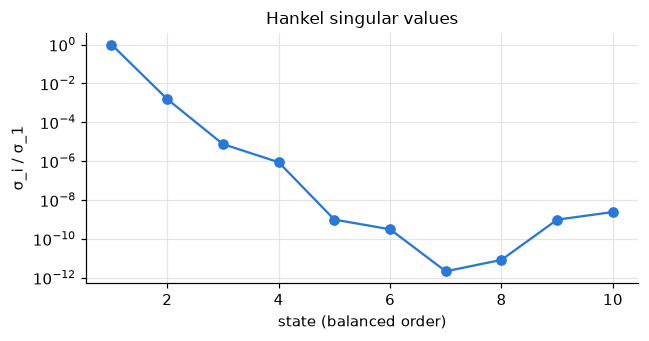

sigma / sigma_1 = [1.0000e+00 1.5495e-03 7.4609e-06 8.7298e-07 9.7198e-10 3.0818e-10 2.1183e-12 8.2216e-12 9.6650e-10
 2.3837e-09]


r = 1: poles [-0.005]; DC gain 0.9523; H-inf bound 2*sum(tail) = 1.48e-03
r = 2: poles [-0.005  -0.0002]; DC gain 0.9508; H-inf bound 2*sum(tail) = 7.94e-06
r = 3: poles [-0.005  -0.0044 -0.0002]; DC gain 0.9508; H-inf bound 2*sum(tail) = 8.36e-07


C:\Users\17asi\miniconda3\envs\PharmaPy\Lib\site-packages\scipy\signal\_filter_design.py:1234: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  b, a = normalize(b, a)


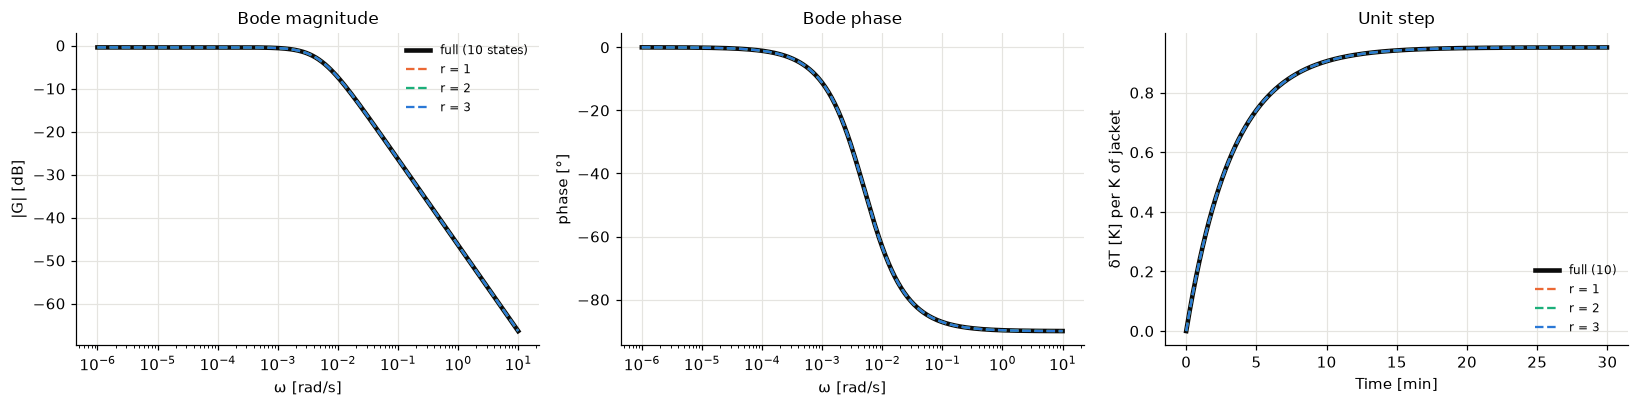

In [7]:
def psd_sqrt(W_):
    # Gramians this ill-conditioned are indefinite at round-off, so Cholesky
    # fails: take the symmetric square root with negative eigenvalues clipped.
    lam_, U_ = np.linalg.eigh((W_ + W_.T) / 2)
    return U_ * np.sqrt(np.clip(lam_, 0.0, None))

def balanced_truncation(A_, B_, C_, r):
    # Square-root balanced truncation. Returns Ar, Br, Cr, the Hankel
    # singular values, and the projection Ti (xr = Ti x).
    Lc = psd_sqrt(linalg.solve_continuous_lyapunov(A_, -B_ @ B_.T))
    Lo = psd_sqrt(linalg.solve_continuous_lyapunov(A_.T, -C_.T @ C_))
    Uh, sig, Vh = np.linalg.svd(Lo.T @ Lc)
    Si = np.diag(sig[:r] ** -0.5)
    T_ = Lc @ Vh.T[:, :r] @ Si
    Ti = Si @ Uh[:, :r].T @ Lo.T
    return Ti @ A_ @ T_, Ti @ B_, C_ @ T_, sig, Ti

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.semilogy(range(1, nr + 1), hsv / hsv[0], "o-", color=C_LQG)
ax.set(xlabel="state (balanced order)", ylabel="σ_i / σ_1", title="Hankel singular values")
plt.tight_layout(); plt.show()
print("sigma / sigma_1 =", hsv / hsv[0])

G_full = signal.StateSpace(red.A, red.B, red.C, 0)
w = np.logspace(-6, 1, 400)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
_, mag_f, ph_f = signal.bode(G_full, w)
ax[0].semilogx(w, mag_f, color=INK, lw=3, label=f"full ({nr} states)")
ax[1].semilogx(w, ph_f, color=INK, lw=3)
tt = np.arange(0, 1800, 2.0)
_, yf = signal.step(G_full, T=tt)
ax[2].plot(tt / 60, yf, color=INK, lw=3, label=f"full ({nr})")
colors = {1: C_PI, 2: "#1baf7a", 3: C_LQG}
reduced_models = {}
for r in (1, 2, 3):
    Ar, Br, Cr, _, _ = balanced_truncation(As, Bs, Cs, r)
    reduced_models[r] = (Ar, Br, Cr)
    Gr = signal.StateSpace(Ar, Br, Cr, 0)
    _, mg, ph = signal.bode(Gr, w)
    ax[0].semilogx(w, mg, color=colors[r], lw=1.5, ls="--", label=f"r = {r}")
    ax[1].semilogx(w, ph, color=colors[r], lw=1.5, ls="--")
    _, yr = signal.step(Gr, T=tt)
    ax[2].plot(tt / 60, yr, color=colors[r], lw=1.5, ls="--", label=f"r = {r}")
    bound = 2 * hsv[r:].sum() / hsv[0] * hsv[0]
    dc_r = (-Cr @ np.linalg.solve(Ar, Br)).item()
    print(f"r = {r}: poles {np.sort(np.linalg.eigvals(Ar).real)}; DC gain {dc_r:.4f}; "
          f"H-inf bound 2*sum(tail) = {bound:.2e}")
ax[0].set(xlabel="ω [rad/s]", ylabel="|G| [dB]", title="Bode magnitude"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="ω [rad/s]", ylabel="phase [°]", title="Bode phase")
ax[2].set(xlabel="Time [min]", ylabel="δT [K] per K of jacket", title="Unit step")
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [8]:
# The transfer function the full state space implies: G(s) = C (sI - A)^-1 B.
z, p, k = signal.ss2zpk(red.A, red.B, red.C, 0)
print("poles  [1/s]:", np.sort_complex(p))
print("zeros  [1/s]:", np.sort_complex(z))
print(f"gain   k = {k:.4e},  DC gain G(0) = {(-red.C @ np.linalg.solve(red.A, red.B)).item():.4f}")
# Pair each zero with the pole nearest to it: near pairs cancel.
left = list(p)
print("\nnearly cancelling pole-zero pairs (|p - z| / |p|):")
for zi in sorted(z, key=lambda v: v.real):
    j = int(np.argmin([abs(pi - zi) for pi in left]))
    pj = left.pop(j)
    print(f"  p = {pj.real:.4e}   z = {zi.real:.4e}   {abs(pj - zi) / abs(pj):.1e}")
print("left over (dominant) poles:", np.sort_complex(np.array(left)),
      " -> tau =", -1 / np.array(left).real)
Ar1, Br1, Cr1 = reduced_models[1]
print(f"\nr = 1 balanced model: G(s) = {(-Cr1 @ np.linalg.solve(Ar1, Br1)).item():.4f} / "
      f"({-1 / Ar1.item():.1f} s + 1)")

poles  [1/s]: [-1.0002e+00+0.0000e+00j -1.1310e-02-5.4178e-05j -1.1310e-02+5.4178e-05j -5.0228e-03+0.0000e+00j
 -2.2484e-04+0.0000e+00j -2.2422e-04-1.0559e-06j -2.2422e-04+1.0559e-06j -2.2298e-04-1.0505e-06j
 -2.2298e-04+1.0505e-06j -2.2237e-04+0.0000e+00j]
zeros  [1/s]: [-1.0002e+00+0.0000e+00j -1.1365e-02+0.0000e+00j -1.1255e-02+0.0000e+00j -2.2446e-04-5.2903e-07j
 -2.2446e-04+5.2903e-07j -2.2353e-04-1.0542e-06j -2.2353e-04+1.0542e-06j -2.2261e-04-5.2498e-07j
 -2.2261e-04+5.2498e-07j]
gain   k = 4.7847e-03,  DC gain G(0) = 0.9508

nearly cancelling pole-zero pairs (|p - z| / |p|):
  p = -1.0002e+00   z = -1.0002e+00   1.0e-10
  p = -1.1310e-02   z = -1.1365e-02   6.8e-03
  p = -1.1310e-02   z = -1.1255e-02   6.8e-03
  p = -2.2422e-04   z = -2.2446e-04   2.6e-03
  p = -2.2422e-04   z = -2.2446e-04   2.6e-03
  p = -2.2298e-04   z = -2.2353e-04   2.5e-03
  p = -2.2298e-04   z = -2.2353e-04   2.5e-03
  p = -2.2237e-04   z = -2.2261e-04   2.6e-03
  p = -2.2484e-04   z = -2.2261e-04   1.0e

**The transfer function falls out of the state space.** $G(s) = C(sI-A)^{-1}B$
has 10 poles and 9 zeros, and every zero sits on top of a pole. F's 1 s mode
cancels to 1e-10, the 88 s level pair to 0.7 % and the residence-time
cluster to 0.3 %. What is left is a single pole at 199 s, so

$$G(s) \approx \frac{0.95}{199\,s + 1}.$$

the same form `CR02R_control_theory.ipynb` *fitted* to CR02R's step test.
(There, $0.958/(201s+1)$.) There it was found from data; here it is
derived. The Hankel singular values agree: $\sigma_2/\sigma_1 = 1.5\times
10^{-3}$, so one state carries nearly all of the input-output behaviour. The
$r = 1$ balanced model, $0.952/(199s+1)$, is indistinguishable from the full
one on the step and Bode plots. (Pole-zero cancellation is also the transfer-function face
of section 4: a mode that is uncontrollable or unobservable cancels out of
$G(s)$. The transfer function hides those modes; the state space does not.)

## 6. State feedback

With the full state available, $u = -Kx$ moves the closed-loop poles to
$\mathrm{eig}(A - BK)$. Only the controllable modes can be moved; the
residence-time cluster stays where it is whatever $K$ is.

To track a temperature set point with no offset, even under model error
and disturbances, the state is augmented with the integral of the tracking
error, $\dot z = r - y$:

$$\begin{bmatrix}\dot x\\ \dot z\end{bmatrix} =
\underbrace{\begin{bmatrix}A & 0\\ -C & 0\end{bmatrix}}_{A_a}
\begin{bmatrix}x\\ z\end{bmatrix} +
\underbrace{\begin{bmatrix}B\\ 0\end{bmatrix}}_{B_a} u +
\begin{bmatrix}0\\ 1\end{bmatrix} r,
\qquad u = -K x - K_z z .$$

### 6a. Pole placement

The design model is the $r = 2$ balanced model plus the integrator, three
states. Its two poles are the temperature mode (−0.005) and a slow
residence-time mode (−0.0002). The poles are put where they are wanted and
the gains read off (Ackermann / `scipy.signal.place_poles`); the gain then
acts on the full model through the balancing projection, to see what
truncation cost.

Two choices of where to put them:
- **naive**: all three poles at $-1/\tau_{cl} \times (1, 1.3, 1.6)$;
- **sensible**: the temperature and integrator poles at
  $-1/\tau_{cl} \times (1, 1.5)$, and the slow pole left where it is.

naive,    tau_cl =  300 s: gains [-7.0787e-01  9.9889e+01 -7.3330e-02]; jacket peak    -7.04 K for a -1 K step
naive,    tau_cl =  120 s: gains [-1.3743e+01  1.7222e+03 -1.1458e+00]; jacket peak   -29.85 K for a -1 K step
sensible, tau_cl =  300 s: gains [ 0.0478  0.009  -0.0035]; full-model max Re(eig) = -2.23e-04; jacket peak  -1.05 K
sensible, tau_cl =  120 s: gains [ 0.2281  0.0577 -0.0218]; full-model max Re(eig) = -2.23e-04; jacket peak  -1.19 K
sensible, tau_cl =   60 s: gains [ 0.5278  0.2375 -0.0872]; full-model max Re(eig) = -2.23e-04; jacket peak  -1.88 K


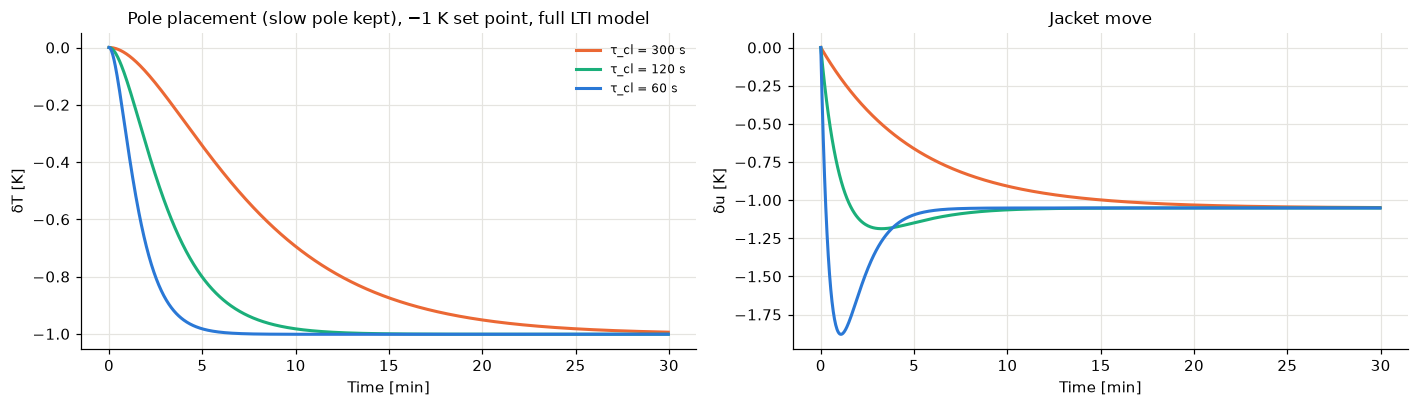

In [9]:
Ar2, Br2, Cr2 = reduced_models[2]
Aa2 = np.block([[Ar2, np.zeros((2, 1))], [-Cr2, np.zeros((1, 1))]])
Ba2 = np.vstack([Br2, [[0.0]]])

# The balancing projection maps the scaled full state to the r = 2 state
# (xr = Ti2 xs), so the gain designed on 2 states acts on the full state.
*_, Ti2 = balanced_truncation(As, Bs, Cs, 2)

lam_slow = np.linalg.eigvals(Ar2).real.max()      # the residence-time pole

def placed(poles):
    Ka = signal.place_poles(Aa2, Ba2, poles).gain_matrix
    Kfull, Kz = Ka[:, :2] @ Ti2, Ka[0, 2]               # on the scaled full state
    Acl = np.block([[As - Bs @ Kfull, -Bs * Kz], [-Cs, np.zeros((1, 1))]])
    Bcl = np.vstack([np.zeros((nr, 1)), [[1.0]]])
    Ccl = np.vstack([np.hstack([Cs, [[0.0]]]), np.hstack([-Kfull, [[-Kz]]])])
    _, y_, _ = signal.lsim((Acl, Bcl, Ccl, np.zeros((2, 1))), -np.ones_like(tt), tt)
    return Ka, Acl, y_

tt = np.arange(0, 1800, 2.0)
for tau_cl in (300.0, 120.0):
    Ka, Acl, y_ = placed(-1 / tau_cl * np.array([1.0, 1.3, 1.6]))
    print(f"naive,    tau_cl = {tau_cl:4.0f} s: gains {Ka.ravel()}; "
          f"jacket peak {y_[:, 1].min():8.2f} K for a -1 K step")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for tau_cl, col in ((300.0, C_PI), (120.0, "#1baf7a"), (60.0, C_LQG)):
    Ka, Acl, y_ = placed(np.r_[-1 / tau_cl * np.array([1.0, 1.5]), lam_slow])
    ax[0].plot(tt / 60, y_[:, 0], color=col, lw=2, label=f"τ_cl = {tau_cl:.0f} s")
    ax[1].plot(tt / 60, y_[:, 1], color=col, lw=2)
    print(f"sensible, tau_cl = {tau_cl:4.0f} s: gains {Ka.ravel()}; "
          f"full-model max Re(eig) = {np.linalg.eigvals(Acl).real.max():.2e}; "
          f"jacket peak {y_[:, 1].min():6.2f} K")
ax[0].set(xlabel="Time [min]", ylabel="δT [K]",
          title="Pole placement (slow pole kept), −1 K set point, full LTI model")
ax[0].legend(fontsize=8)
ax[1].set(xlabel="Time [min]", ylabel="δu [K]", title="Jacket move")
plt.tight_layout(); plt.show()

**Moving a weakly controllable pole is expensive.** The naive placement drags
the slow residence-time pole ~20× faster, and the price is a jacket swing of
7 K (300 s) to 30 K (120 s) per kelvin of set point, with gains in the
thousands. That is the PBH number from section 4 at work: the less
controllable a mode, the more input it takes to move it. Leaving it alone
gives sensible gains, and the full model stays stable, so truncating to
$r = 2$ cost nothing. Faster poles still cost larger jacket moves. Pole
placement gives exact poles but no say in that trade-off, and with many
states it is unclear where the poles should go. LQR answers both.

### 6b. LQR with integral action (LQI)

Minimize
$$J = \int_0^\infty \left(q_T\,\delta T^2 + q_z\,z^2 + r_u\,\delta u^2\right) dt$$
over $u = -K_a x_a$. The optimum comes from the algebraic Riccati equation
$A_a^TP + PA_a - PB_aR^{-1}B_a^TP + Q = 0$, with $K_a = R^{-1}B_a^TP$. It is
designed on the 10-state model (the absent species dropped), in scaled
coordinates. LQR on a stabilizable plant always gives a stable loop, with
guaranteed margins at the plant input: gain margin $[\tfrac12, \infty)$ and
phase margin $\ge 60°$.

weights: {'q_temp': 1.0, 'q_integral': 0.0002777777777777778, 'r_input': 0.05}
K  (physical units, K of jacket per unit of state):
   m_A          -2.2643e-02
   m_D          -1.1017e-02
   m_E          -7.8097e-03
   m_F           9.4054e+01
   m_G          -3.0095e-02
   m_H          -3.9330e-02
   m_I          -1.9940e-02
   m_J          -1.9515e-02
   T             6.1790e+00
   I_lvl         1.2650e-01
Kz = -7.4536e-02 1/s

closed-loop eigenvalues (state feedback): [-1.0002e+00+0.j     -1.7294e-02-0.0076j -1.7294e-02+0.0076j -1.1355e-02+0.j     -1.1264e-02+0.j
 -2.2358e-04+0.j     -2.2358e-04+0.j     -2.2358e-04+0.j     -2.2358e-04+0.j     -2.2358e-04+0.j
 -2.2329e-04+0.j    ]
open-loop eigenvalues               : [-1.0002e+00+0.0000e+00j -1.1310e-02-5.4178e-05j -1.1310e-02+5.4178e-05j -5.0228e-03+0.0000e+00j
 -2.2391e-04+0.0000e+00j -2.2358e-04+0.0000e+00j -2.2358e-04-8.8622e-14j -2.2358e-04+8.8622e-14j
 -2.2358e-04+0.0000e+00j -2.2336e-04+0.0000e+00j]


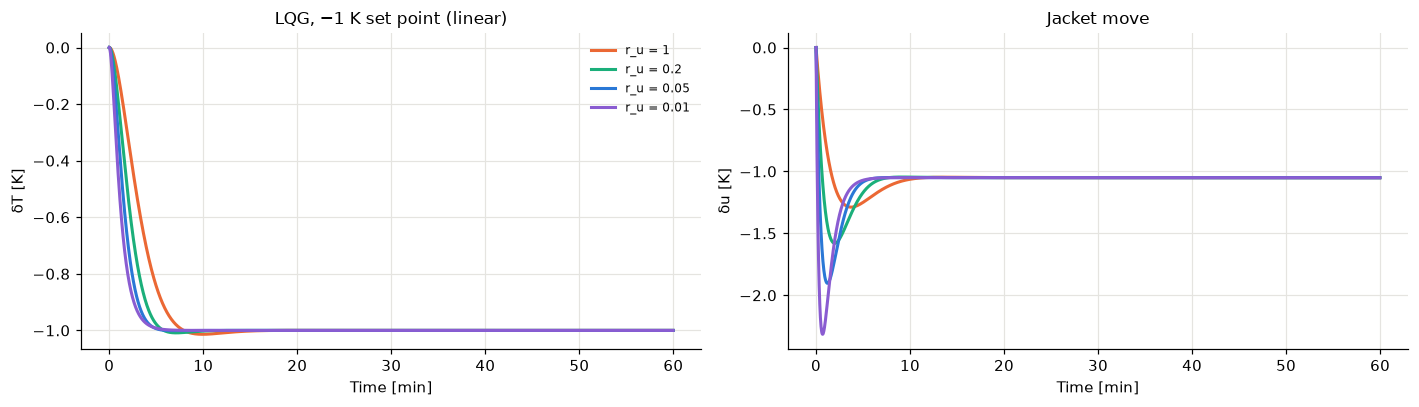

   r_u  t63 [s]  jacket peak [K]  overshoot
     1      210            -1.29      1.37%
   0.2      144            -1.58      0.86%
  0.05      108            -1.90      0.08%
  0.01       84            -2.31     -0.00%


In [10]:
design = ss.design_lqg(model)
print("weights:", ss.LQ_WEIGHTS)
print("K  (physical units, K of jacket per unit of state):")
for lab_, k_ in zip(rlab, design.K):
    print(f"   {lab_:<12} {k_: .4e}")
print(f"Kz = {design.Kz:.4e} 1/s")

Aa = np.block([[As, np.zeros((nr, 1))], [-Cs, np.zeros((1, 1))]])
Ba = np.vstack([Bs, [[0.0]]])
eig_cl = np.linalg.eigvals(Aa - Ba @ design.Ka_scaled)
print("\nclosed-loop eigenvalues (state feedback):", np.sort_complex(eig_cl))
print("open-loop eigenvalues               :", np.sort_complex(lam))

# Trade-off: speed against jacket effort, over the input weight.
tt = np.arange(0, 3600, 2.0)
rows = []
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for r_u, col in ((1.0, C_PI), (0.2, "#1baf7a"), (0.05, C_LQG), (0.01, "#8a5cd1")):
    d_ = ss.design_lqg(model, weights=dict(ss.LQ_WEIGHTS, r_input=r_u))
    _, y_, _ = signal.lsim(ss.lqg_closed_loop(d_),
                           np.column_stack([-np.ones_like(tt), 0 * tt]), tt)
    t63 = tt[np.argmax(y_[:, 0] < -0.632)]
    rows.append((r_u, t63, y_[:, 1].min(), -y_[:, 0].min() - 1))
    ax[0].plot(tt / 60, y_[:, 0], color=col, lw=2, label=f"r_u = {r_u:g}")
    ax[1].plot(tt / 60, y_[:, 1], color=col, lw=2)
ax[0].set(xlabel="Time [min]", ylabel="δT [K]", title="LQG, −1 K set point (linear)"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="Time [min]", ylabel="δu [K]", title="Jacket move")
plt.tight_layout(); plt.show()
print(f"{'r_u':>6} {'t63 [s]':>8} {'jacket peak [K]':>16} {'overshoot':>10}")
for r_u, t63, up, ov in rows:
    print(f"{r_u:6g} {t63:8.0f} {up:16.2f} {ov:10.2%}")

**The LQR trade-off is one dial.** Lowering $r_u$ (cheaper jacket moves)
speeds the loop and enlarges the jacket swing, with overshoot under 1.5 %
throughout. The design used from here on is $r_u = 0.05$: 63 % of a step
in 108 s, for a jacket peak 1.9× the set-point change.

**Only the temperature mode moves.** With the integrator it becomes the
pair −0.017 ± 0.008j (τ ≈ 58 s, well damped). F's mode, the level pair and
the residence-time cluster are where they were, as section 4 predicted: no
gain can move a mode the input cannot reach. The gains on D, E, H, I and J
are small for the same reason. The large gain on F is per kg of a 1.9 g
inventory, so it matters little in practice.

## 7. State estimation: the Kalman filter

$u = -Kx$ needs every mass, but only $T$ is measured. An observer runs a copy
of the model and corrects it with the measurement:

$$\dot{\hat x} = A\hat x + Bu + L\,(y - C\hat x),$$

so the estimation error $e = x - \hat x$ obeys $\dot e = (A - LC)\,e$. Any $L$
that makes $A - LC$ stable gives $\hat x \to x$; observability is what lets
$L$ place those poles. The **Kalman filter** chooses $L$ optimally for given
noise levels. Here the process noise is the feed temperature wandering by
$\sigma_d$ = 2 K plus a small unmodelled drift on every state, and the
thermometer noise is $\sigma_y$ = 0.05 K. $L = P C^T V^{-1}$, with $P$ from
the filter Riccati equation, the dual of the LQR one. The steady-state
error covariance $P$ says how well each state can be known, compared with
running the model with no measurement at all.

noise: {'sigma_d': 2.0, 'sigma_model': 0.001, 'sigma_y': 0.05}   (disturbance random walk: 0.05 K/sqrt(s))
L  (physical units, per K of innovation, per s):
   m_A          -2.5278e-05
   m_D           1.4559e-04
   m_E           8.1183e-05
   m_F           2.7537e-09
   m_G          -5.8353e-05
   m_H          -4.7356e-05
   m_I          -5.8624e-06
   m_J          -4.3178e-06
   T             1.6470e-02
   I_lvl         4.6466e-07

observer eigenvalues eig(A - LC): [-1.0002e+00+0.j -2.1492e-02+0.j -1.1380e-02+0.j -1.1240e-02+0.j -2.2428e-04+0.j -2.2358e-04+0.j
 -2.2358e-04+0.j -2.2358e-04+0.j -2.2358e-04+0.j -2.2317e-04+0.j]

state         std, open loop  std, Kalman  reduction
m_A                1.895e-03    1.893e-03       1.00
m_D                1.161e-02    1.158e-02       1.00
m_E                1.147e-02    1.146e-02       1.00
m_F                6.723e-07    6.723e-07       1.00
m_G                4.330e-03    4.326e-03       1.00
m_H                4.606e-03    4.606e-03      

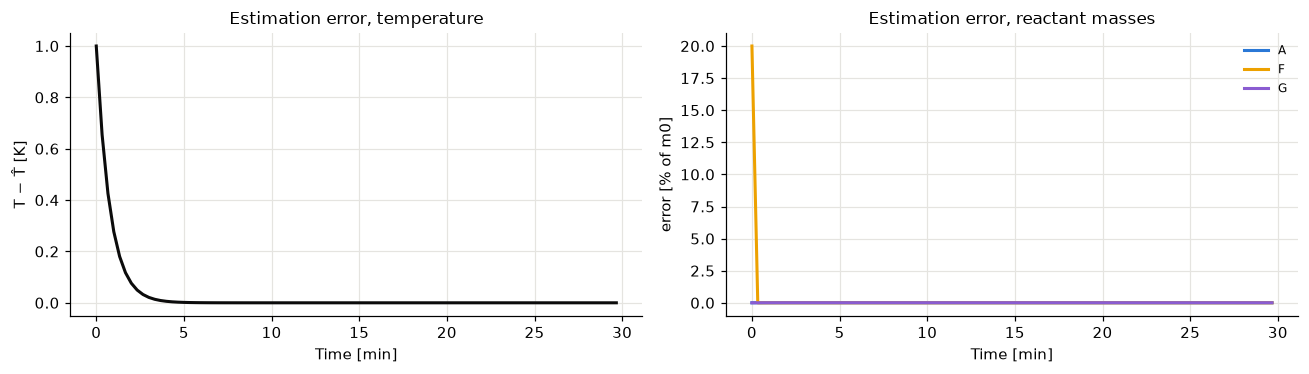

In [11]:
print("noise:", ss.KF_NOISE, "  (disturbance random walk:", ss.SIGMA_D_WALK, "K/sqrt(s))")
print("L  (physical units, per K of innovation, per s):")
for lab_, l_ in zip(rlab, design.L):
    print(f"   {lab_:<12} {l_: .4e}")
Ls = design.Ls_scaled
eig_obs = np.linalg.eigvals(As - Ls @ Cs)
print("\nobserver eigenvalues eig(A - LC):", np.sort_complex(eig_obs))

# How well each state can be estimated: the steady-state error covariance.
W_ = ss.KF_NOISE["sigma_d"]**2 * Es @ Es.T + ss.KF_NOISE["sigma_model"]**2 * np.eye(nr)
V_ = np.array([[ss.KF_NOISE["sigma_y"]**2]])
Pf = linalg.solve_continuous_are(As.T, Cs.T, W_, V_)
P_open = linalg.solve_continuous_lyapunov(As, -W_)       # no measurement at all
print(f"\n{'state':<12} {'std, open loop':>15} {'std, Kalman':>12} {'reduction':>10}")
for i, lab_ in enumerate(rlab):
    so_, sk_ = np.sqrt(P_open[i, i]) * s_[i], np.sqrt(Pf[i, i]) * s_[i]
    print(f"{lab_:<12} {so_:15.3e} {sk_:12.3e} {sk_ / so_:10.2f}")

# Convergence from a wrong initial estimate (linear model, no noise):
# the filter starts believing T is 1 K high and F 20 % high.
Aobs = red.A - np.outer(design.L, design.C)
e0 = np.zeros(nr); e0[rlab.index("T")] = 1.0; e0[rlab.index("m_F")] = 0.2 * x0[names.index("F")]
tt = np.arange(0, 1800, 2.0)
E_t = np.array([linalg.expm(Aobs * ti) @ e0 for ti in tt[::10]])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(tt[::10] / 60, E_t[:, rlab.index("T")], color=INK, lw=2)
ax[0].set(xlabel="Time [min]", ylabel="T − T̂ [K]", title="Estimation error, temperature")
for s in ("A", "F", "G"):
    i = rlab.index(f"m_{s}")
    ax[1].plot(tt[::10] / 60, E_t[:, i] / x0[names.index(s)] * 100, color=SPECIES_COLORS[s], lw=2,
               label=s)
ax[1].set(xlabel="Time [min]", ylabel="error [% of m0]", title="Estimation error, reactant masses")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**The thermometer tells the filter about the temperature, and little else.**
The measurement cuts the temperature's uncertainty (to 0.62 of open loop),
but every mass stays at 1.00: from $T$ alone the masses are not observable
in any useful sense, just as section 4 found. Only the temperature
eigenvalue of $A - LC$ moves (to about −0.021, a 47 s time constant); every
other observer eigenvalue is a plant eigenvalue. So the filter estimates
the masses by **running the model** on the known jacket input, and an
error in a mass estimate dies away only at the plant's own rate: 1 s for F,
88 s for the level, 75 min for the products.

That is enough as long as the model knows every input. An unmeasured
disturbance is a different matter.

### 7b. Unmeasured disturbances bias the estimate

When the feed temperature steps and the filter is not told, the
temperature rises for no reason the model knows. A constant error
$y - C\hat x$ is then needed to hold the estimate near the measurement, and
through $L$ it keeps pushing every mass estimate away from the truth. The
estimate is **biased** for as long as the disturbance lasts.

The standard fix is to give the filter a model of the disturbance: append
$d$ as a state with $\dot d = w$ (a random walk), so $A_o =
\begin{bmatrix}A & E\\ 0 & 0\end{bmatrix}$, $C_o = [C\;\;0]$. The augmented
pair is observable because $d$ moves $T$ at steady state ($G_d(0) \neq 0$).
The filter now *estimates the feed temperature* and explains the
temperature rise correctly. The controller gain on $\hat d$ is zero here,
since the integral already removes the offset; feeding $\hat d$ forward
would be the next step.

plain filter        : worst estimation error  m_A 1.9e-02 kg, m_D 6.9e-02 kg, T 0.201 K
filter estimating d : worst estimation error  m_A 1.4e-05 kg, m_D 3.5e-05 kg, T 0.110 K


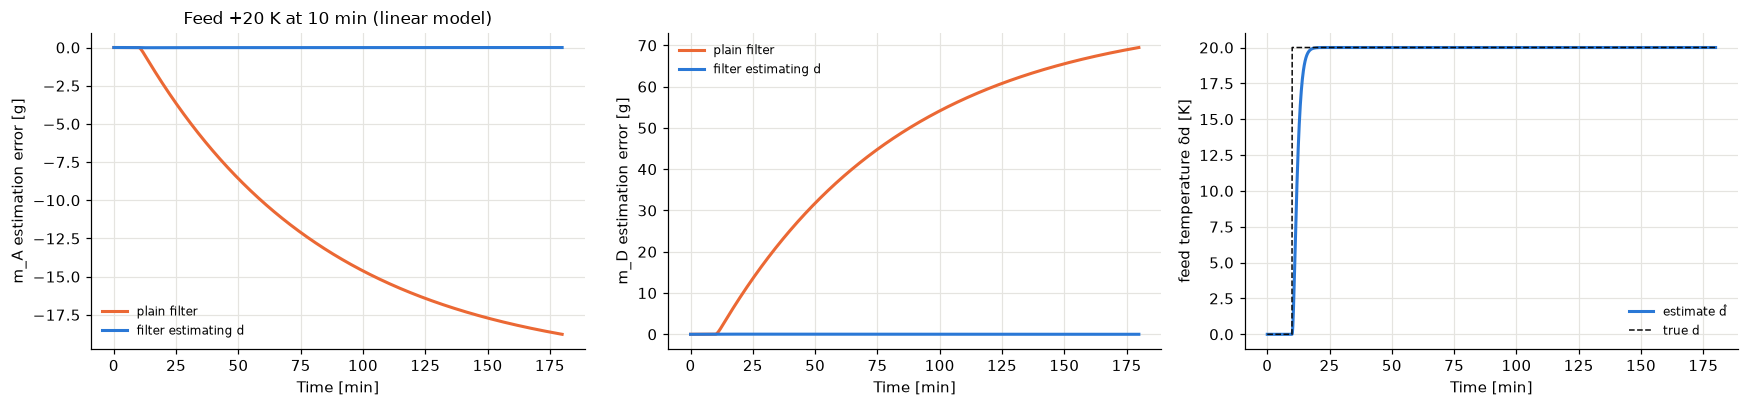

In [12]:
design_d = ss.design_lqg(model, disturbance=True)
t7 = np.arange(0, 3 * 3600, 5.0)
U7 = np.column_stack([0 * t7, ss.CL_DD * (t7 >= 600)])     # feed +20 K at 10 min
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for d_, col, lab in ((design, C_PI, "plain filter"), (design_d, C_LQG, "filter estimating d")):
    Acl_, Bcl_, Ccl_, _ = ss.lqg_closed_loop(d_)
    no_ = d_.Ao.shape[0]
    Cx = np.zeros((nr + no_, Acl_.shape[0]))
    Cx[:nr, :nr] = np.eye(nr); Cx[nr:, nr:nr + no_] = np.eye(no_)
    _, Y7, _ = signal.lsim((Acl_, Bcl_, np.vstack([Ccl_, Cx]), np.zeros((2 + nr + no_, 2))), U7, t7)
    x_, xh_ = Y7[:, 2:2 + nr], Y7[:, 2 + nr:]
    for a, st_ in ((ax[0], "m_A"), (ax[1], "m_D")):
        i = rlab.index(st_)
        a.plot(t7 / 60, (xh_[:, i] - x_[:, i]) * 1e3, color=col, lw=2, label=lab)
    if d_.disturbance:
        ax[2].plot(t7 / 60, xh_[:, nr], color=col, lw=2, label="estimate d̂")
    err = np.abs(xh_[:, :nr] - x_).max(axis=0)
    print(f"{lab:<20}: worst estimation error  m_A {err[rlab.index('m_A')]:.1e} kg, "
          f"m_D {err[rlab.index('m_D')]:.1e} kg, T {err[rlab.index('T')]:.3f} K")
ax[2].plot(t7 / 60, U7[:, 1], color=INK, lw=1, ls="--", label="true d")
for a, t_ in zip(ax, ("m_A estimation error [g]", "m_D estimation error [g]", "feed temperature δd [K]")):
    a.set(xlabel="Time [min]", ylabel=t_); a.legend(fontsize=8)
ax[0].set_title("Feed +20 K at 10 min (linear model)")
plt.tight_layout(); plt.show()

With the plain filter the estimates drift off as soon as the feed steps, by
as much as the masses themselves move. With the disturbance state the
filter finds the 20 K step in a few minutes, and the mass estimates stay on
the truth to a few hundredths of a gram. Both versions run in PharmaPy in
section 9.

## 8. LQG: the regulator and the filter together

Feeding the estimate to the LQR gain, $u = -K\hat x - K_z z$, gives the
LQG controller. In the coordinates $(x, e = x - \hat x, z)$ the closed loop is
block triangular, so

$$\mathrm{eig}(\text{closed loop}) = \mathrm{eig}(A_a - B_aK_a)\;\cup\;\mathrm{eig}(A - LC).$$

This is the **separation principle**: the regulator and the observer can be
designed independently and the poles simply combine. What does *not*
combine is robustness. LQR's guaranteed margins do not survive the
observer (Doyle, 1978: "there are none"), so the margins of the LQG loop
have to be checked. The loop is broken at the plant input:
$L(s) = K_{LQG}(s)\,G(s)$.

separation principle: max |eig(LQG) - [eig(LQR) ∪ eig(KF)]| = 2.30e-13 1/s



loop    PM [deg]       GM  w_c [rad/s]     Ms  delay margin [s]
LQR         78.0      inf       0.0313   1.00                44
LQG         59.9      inf       0.0170   1.25                61
LQG+d       51.2      inf       0.0198   1.33                45
PI          90.7      inf       0.0191   1.00                83


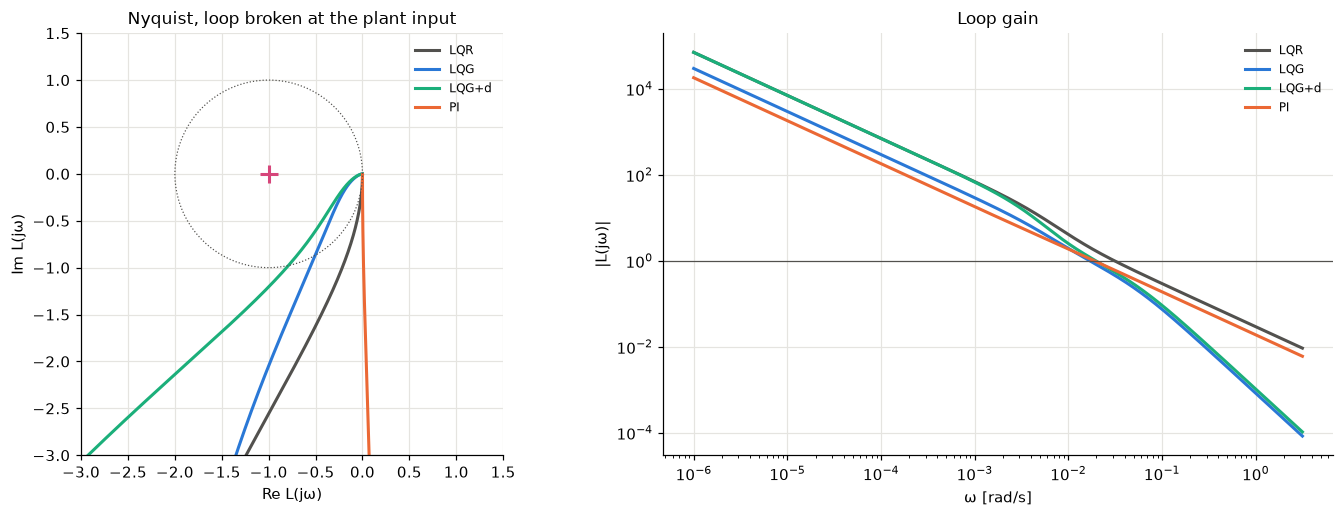

In [13]:
Acl, Bcl, Ccl, _ = ss.lqg_closed_loop(design)
eig_lqg = np.sort_complex(np.linalg.eigvals(Acl))
union = np.sort_complex(np.r_[eig_cl, eig_obs])
print("separation principle: max |eig(LQG) - [eig(LQR) ∪ eig(KF)]| =",
      f"{np.abs(eig_lqg - union).max():.2e} 1/s")

# Loop transfer at the plant input. Controller: input y (and r = 0), output u.
def controller_ss(d_):
    # xhat' = (Ao - L Co - Bo Ko) xhat - Bo Kz z + L y;  z' = -y;  u = -Ko xhat - Kz z
    Ao_, Bo_, Co_ = d_.Ao, d_.Bo[:, None], d_.Co[None, :]
    Ko_, L_, Kz_ = d_.Ko[None, :], d_.L[:, None], d_.Kz
    no_ = Ao_.shape[0]
    Ak = np.block([[Ao_ - L_ @ Co_ - Bo_ @ Ko_, -Bo_ * Kz_], [np.zeros((1, no_ + 1))]])
    Bk = np.vstack([L_, [[-1.0]]])
    Ck = np.hstack([-Ko_, [[-Kz_]]])
    return Ak, Bk, Ck

Ar_, Br_, Cr_ = design.A, design.B[:, None], design.C[None, :]
w = np.logspace(-6, 0.5, 3000)
def freq(Am, Bm, Cm, w_):
    return np.array([(Cm @ np.linalg.solve(1j * wi * np.eye(Am.shape[0]) - Am, Bm)).item() for wi in w_])
Gjw = freq(Ar_, Br_, Cr_, w)
L_lqg = -freq(*controller_ss(design), w) * Gjw      # negative feedback convention
L_lqgd = -freq(*controller_ss(design_d), w) * Gjw
# LQR loop (full state): L = Ka (sI - Aa)^-1 Ba, scaled coordinates.
L_lqr = freq(Aa, Ba, design.Ka_scaled, w)
# PharmaPy's PI: C(s) = Kc (1 + 1/(Ti s)).
cl = np.load(DATA / "closed_loop.npz")
kc, ti = float(cl["pi_kc"]), float(cl["pi_ti"])
L_pi = kc * (1 + 1 / (ti * 1j * w)) * Gjw

def margins(Lw, w_):
    mag = np.abs(Lw)
    i = np.nonzero(np.diff(np.sign(mag - 1)))[0]
    pm = 180 + np.degrees(np.angle(Lw[i[-1]])) if len(i) else np.inf
    wc = w_[i[-1]] if len(i) else np.nan
    ph = np.unwrap(np.angle(Lw))
    j = np.nonzero(np.diff(np.sign(ph + np.pi)))[0]
    gm = 1 / mag[j[0]] if len(j) else np.inf
    ms = 1 / np.abs(1 + Lw).min()
    return pm, gm, wc, ms

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
print(f"\n{'loop':<6} {'PM [deg]':>9} {'GM':>8} {'w_c [rad/s]':>12} {'Ms':>6} {'delay margin [s]':>17}")
for name_, Lw, col in (("LQR", L_lqr, MUTED), ("LQG", L_lqg, C_LQG),
                       ("LQG+d", L_lqgd, "#1baf7a"), ("PI", L_pi, C_PI)):
    pm, gm, wc, ms = margins(Lw, w)
    dm = np.radians(pm) / wc if np.isfinite(pm) else np.inf
    print(f"{name_:<6} {pm:9.1f} {gm:8.2f} {wc:12.4f} {ms:6.2f} {dm:17.0f}")
    ax[0].plot(Lw.real, Lw.imag, color=col, lw=2, label=name_)
    ax[1].loglog(w, np.abs(Lw), color=col, lw=2, label=name_)
th = np.linspace(0, 2 * np.pi, 200)
ax[0].plot(-1 + np.cos(th), np.sin(th), color=MUTED, lw=0.8, ls=":")
ax[0].plot([-1], [0], "+", color="#d6457a", ms=12, mew=2)
ax[0].set(xlim=(-3, 1.5), ylim=(-3, 1.5), xlabel="Re L(jω)", ylabel="Im L(jω)",
          title="Nyquist, loop broken at the plant input"); ax[0].set_aspect("equal")
ax[0].legend(fontsize=8)
ax[1].axhline(1, color=MUTED, lw=0.8)
ax[1].set(xlabel="ω [rad/s]", ylabel="|L(jω)|", title="Loop gain"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The separation principle holds to round-off. On robustness:
- **LQR** (full state): phase margin 78°, infinite gain margin, $M_s$ = 1,
  outside the unit circle around −1, as LQR always is.
- **LQG**: the observer costs margin, as Doyle warned. The phase margin drops
  to 60° and $M_s$ rises to 1.25, still comfortable, with a 61 s delay margin.
  The disturbance-estimating version ("LQG+d") gives up a little more
  (51°, $M_s$ = 1.33, 45 s delay margin): its faster-reacting estimate adds
  phase lag around crossover.
- **PharmaPy's PI** is a pole-zero cancellation ($T_i = m c_p/(UA)$ = 209 s
  against the 199 s pole), so its loop is nearly a pure integrator: phase
  margin 91°, $M_s$ = 1, 83 s delay margin, just as for CR02R.

LQG buys its smaller jacket moves (next section) with a little robustness.

## 9. Nonlinear validation: LQG inside PharmaPy

`ss.LQGController` is a PharmaPy controller. Its observer state $\hat x$
(10 entries, 11 with the disturbance) and integral $z$ are declared as
**solver states**, so CVode
integrates the Kalman filter together with the nonlinear plant, and the
results replay reproduces it, exactly as PharmaPy does for its own PI
integrals. It writes the jacket temperature through
`MultiPhaseVessel.UTILITY_TEMPERATURE` like PharmaPy's jacket loop, clipped
to the utility's limits with back-calculation anti-windup. The feed
temperature disturbance enters as an inlet override
(`OperatingKey("temp", ..., port="inlet")`).

Three controllers, each run from $x_0$: PharmaPy's PI jacket loop, LQG with
the plain filter, and LQG with the disturbance-estimating filter ("LQG+d").
- **0.25 h**: set point −2 K;
- **2.5 h**: feed temperature +20 K (unmeasured).

The thin black lines are the linear closed-loop predictions from sections
6–8 for the same inputs.

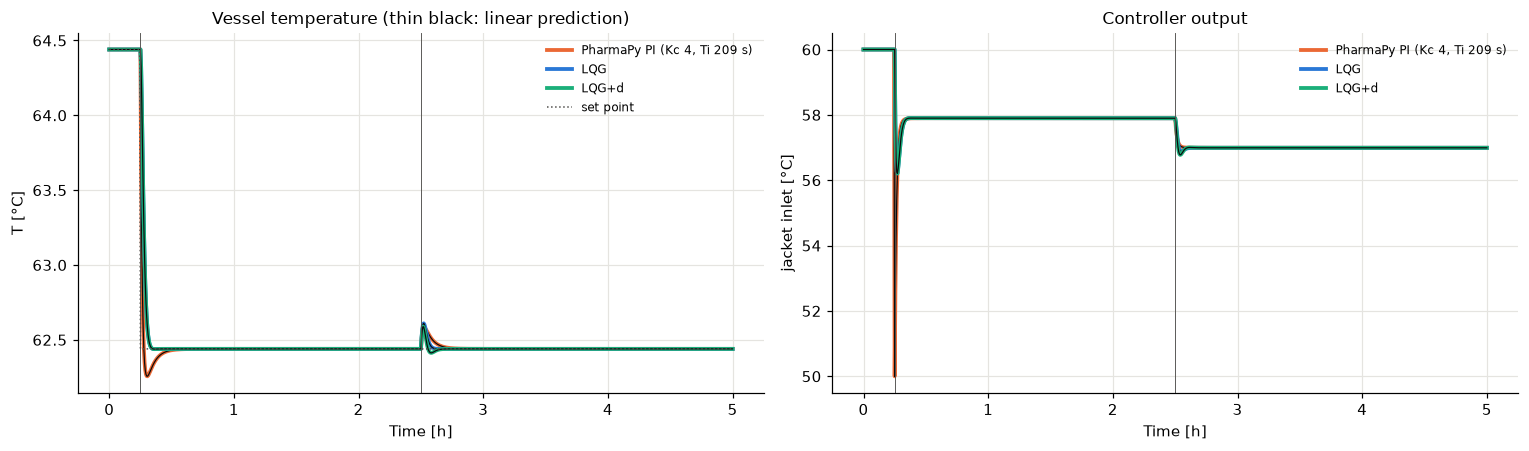

      overshoot  2% settle  IAE (sp) jacket move dist. peak IAE (dist) |NL - lin|
                     [min]     [K s]         [K]        [K]      [K s]       [mK]
PI         9.2%        9.7       129       10.00      0.141       47.2       0.04
LQG        0.1%        4.3       194        3.79      0.171       28.8       0.06
LQGD       0.1%        4.3       194        3.79      0.149       23.1       0.06

wall time: PI 5 s, LQG 6 s, LQG+d 7 s (the LQG runs integrate 11 and 12 extra states)


In [14]:
r_dev = cl["r"] - design.y0
d_dev = cl["d"] - model.d0
res = {}
for tag, sys_cl in (("lqg", ss.lqg_closed_loop(design)),
                   ("lqgd", ss.lqg_closed_loop(design_d)),
                   ("pi", ss.pi_closed_loop(design, kc, ti))):
    t_, T_, u_, r_, d_ = uniform(cl[f"{tag}_time"], cl[f"{tag}_temp"], cl[f"{tag}_u"],
                                 np.interp(cl[f"{tag}_time"], cl["lqg_time"], r_dev),
                                 np.interp(cl[f"{tag}_time"], cl["lqg_time"], d_dev))
    _, Ylin, _ = signal.lsim(sys_cl, np.column_stack([r_, d_]), t_, interp=False)
    # (the r and d steps are on the saved grid, so the zero-order hold is exact)
    res[tag] = dict(t=t_, T=T_, u=u_, T_lin=design.y0 + Ylin[:, 0], u_lin=model.u0 + Ylin[:, 1],
                    r=design.y0 + r_)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
RUNS = (("pi", C_PI, f"PharmaPy PI (Kc {kc:g}, Ti {ti:.0f} s)"), ("lqg", C_LQG, "LQG"),
        ("lqgd", "#1baf7a", "LQG+d"))
for tag, col, lab in RUNS:
    R = res[tag]
    ax[0].plot(R["t"] / 3600, R["T"] - 273.15, color=col, lw=2.5, label=lab)
    ax[0].plot(R["t"] / 3600, R["T_lin"] - 273.15, color=C_LIN, lw=0.8)
    ax[1].plot(R["t"] / 3600, R["u"] - 273.15, color=col, lw=2.5, label=lab)
    ax[1].plot(R["t"] / 3600, R["u_lin"] - 273.15, color=C_LIN, lw=0.8)
ax[0].plot(res["lqg"]["t"] / 3600, res["lqg"]["r"] - 273.15, color=MUTED, lw=1, ls=":", label="set point")
ax[0].set(ylabel="T [°C]", xlabel="Time [h]", title="Vessel temperature (thin black: linear prediction)")
ax[1].set(ylabel="jacket inlet [°C]", xlabel="Time [h]", title="Controller output")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
for a in ax:
    a.axvline(ss.CL_T_R / 3600, color=MUTED, lw=0.6); a.axvline(ss.CL_T_D / 3600, color=MUTED, lw=0.6)
plt.tight_layout(); plt.show()

def metrics(R):
    t_, T_, u_ = R["t"], R["T"], R["u"]
    a = (t_ >= ss.CL_T_R) & (t_ < ss.CL_T_D)
    step_ = ss.CL_DR
    final = design.y0 + step_
    over = max(0.0, (final - T_[a].min()) / abs(step_))
    band = 0.02 * abs(step_)
    out_ = np.nonzero(np.abs(T_[a] - final) > band)[0]
    settle = (t_[a][out_[-1] + 1] - ss.CL_T_R) if len(out_) else 0.0
    b = t_ >= ss.CL_T_D
    return dict(overshoot=over, settle=settle,
                iae_sp=np.trapezoid(np.abs(T_[a] - final), t_[a]),
                du_peak=np.abs(u_[a] - model.u0).max(),
                dist_peak=np.abs(T_[b] - final).max(),
                iae_d=np.trapezoid(np.abs(T_[b] - final), t_[b]),
                lin_err=np.abs(R["T"] - R["T_lin"]).max())

print(f"{'':<5}{'overshoot':>10}{'2% settle':>11}{'IAE (sp)':>10}{'jacket move':>12}"
      f"{'dist. peak':>11}{'IAE (dist)':>11}{'|NL - lin|':>11}")
print(f"{'':<5}{'':>10}{'[min]':>11}{'[K s]':>10}{'[K]':>12}{'[K]':>11}{'[K s]':>11}{'[mK]':>11}")
for tag in ("pi", "lqg", "lqgd"):
    m = metrics(res[tag])
    print(f"{tag.upper():<5}{m['overshoot']:10.1%}{m['settle'] / 60:11.1f}{m['iae_sp']:10.0f}"
          f"{m['du_peak']:12.2f}{m['dist_peak']:11.3f}{m['iae_d']:11.1f}{m['lin_err'] * 1e3:11.2f}")
print(f"\nwall time: PI {float(cl['pi_wall']):.0f} s, LQG {float(cl['lqg_wall']):.0f} s, "
      f"LQG+d {float(cl['lqgd_wall']):.0f} s (the LQG runs integrate "
      f"{len(design.K) + 1} and {len(design_d.Ko) + 1} extra states)")

**The LTI design carries over to the nonlinear plant.** For all three
controllers the PharmaPy run and the linear prediction lie on top of each
other (the last column of the table). That is the real test of the LTI
assumption: a 2 K set-point move and a 20 K feed-temperature swing are well
inside its range for R02R.

**PI vs LQG.** PharmaPy's PI loop overshoots by about 9 % because the set
point enters the jacket directly as the bias, so the jacket first jumps by
$(1 + K_c)\,\Delta r$ = 10 K (the feedforward kick analysed for CR02R). The
LQG loop moves the jacket by under 4 K, does not overshoot, and settles in
under half the time. It is slower off the mark, so its set-point IAE is
higher. Both reject the feed disturbance with no offset, thanks to integral
action. LQG lets the temperature rise slightly further (0.17 against
0.14 K) but brings it back faster, for a lower IAE. Estimating the
disturbance helps the temperature too (peak 0.15 K, IAE 23 against 29 K s),
although $\hat d$ is not fed forward: the estimate no longer fights the
measurement. The bigger change is in the estimate, below.

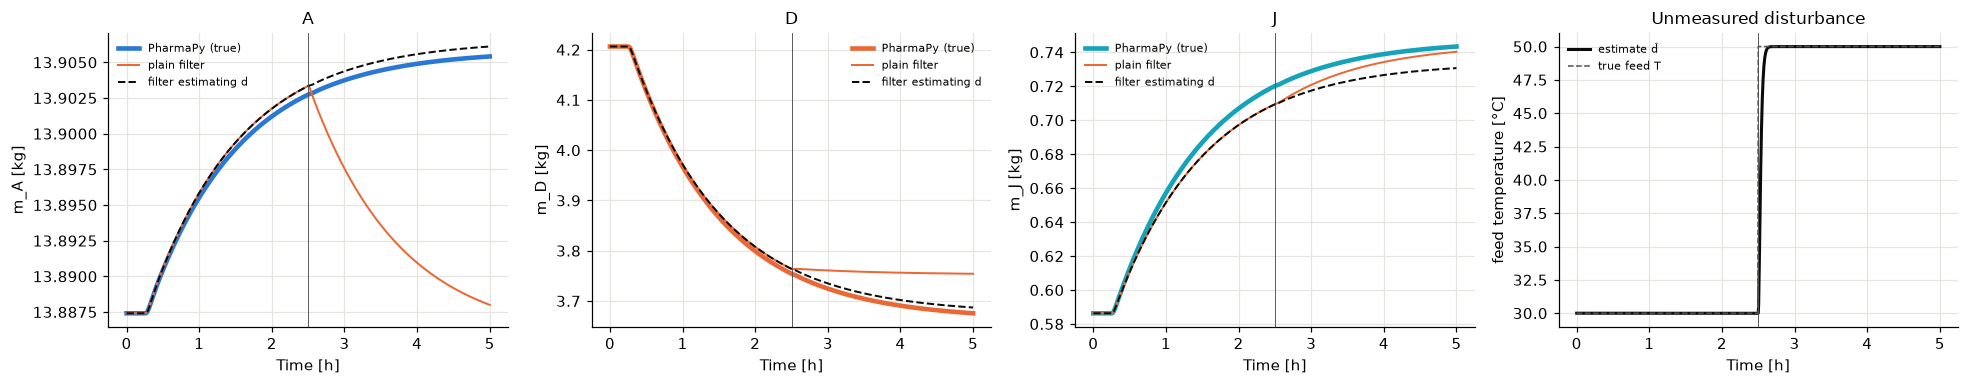

state   moves [kg]  plain filter  estimating d   worst error, % of the move
m_A      1.800e-02           97%            4%
m_D      5.307e-01           15%            2%
m_E      5.091e-01           22%            0%
m_G      4.173e-02           96%            4%
m_J      1.571e-01            7%            8%

feed temperature estimate, from 30 min after the step: 49.99 °C (true 50.00 °C)


In [15]:
keep = list(cl["keep"])
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, s in zip(ax[:3], ("A", "D", "J")):
    j = names.index(s); i = keep.index(j)
    a.plot(cl["lqgd_time"] / 3600, cl["lqgd_mass"][:, j], color=SPECIES_COLORS[s], lw=3,
           label="PharmaPy (true)")
    a.plot(cl["lqg_time"] / 3600, x0[j] + cl["lqg_xhat"][:, i], color=C_PI, lw=1.3,
           label="plain filter")
    a.plot(cl["lqgd_time"] / 3600, x0[j] + cl["lqgd_xhat"][:, i], color=INK, lw=1.3, ls="--",
           label="filter estimating d")
    a.set(xlabel="Time [h]", ylabel=f"m_{s} [kg]", title=f"{s}")
    a.legend(fontsize=7)
ax[3].plot(cl["lqgd_time"] / 3600, model.d0 + cl["lqgd_xhat"][:, -1] - 273.15, color=INK, lw=2,
           label="estimate d̂")
ax[3].plot(cl["lqgd_time"] / 3600, cl["d"] - 273.15, color=MUTED, lw=1, ls="--", label="true feed T")
ax[3].set(xlabel="Time [h]", ylabel="feed temperature [°C]", title="Unmeasured disturbance")
ax[3].legend(fontsize=7)
for a in ax:
    a.axvline(ss.CL_T_D / 3600, color=MUTED, lw=0.6)
plt.tight_layout(); plt.show()

print(f"{'state':<6}{'moves [kg]':>12}{'plain filter':>14}{'estimating d':>14}   worst error, % of the move")
for s in ("A", "D", "E", "G", "J"):
    j = names.index(s); i = keep.index(j)
    move = np.ptp(cl["lqgd_mass"][:, j])
    e1 = np.abs(x0[j] + cl["lqg_xhat"][:, i] - cl["lqg_mass"][:, j]).max()
    e2 = np.abs(x0[j] + cl["lqgd_xhat"][:, i] - cl["lqgd_mass"][:, j]).max()
    print(f"m_{s:<4}{move:12.3e}{e1 / move:14.0%}{e2 / move:14.0%}")
dh = model.d0 + cl["lqgd_xhat"][:, -1]
after = cl["lqgd_time"] > ss.CL_T_D + 1800
print(f"\nfeed temperature estimate, from 30 min after the step: "
      f"{dh[after].mean() - 273.15:.2f} °C (true {cl['d'][-1] - 273.15:.2f} °C)")

**In the nonlinear plant, the estimates behave as the linear analysis said.**
Before the feed steps, both filters track the masses: they run the model
on the known jacket input, and the model is good. After the step, the plain
filter's estimates of the reactants A and G run off by about as much as
they move (96–97 %), while the products stay closer (7–22 %). The filter that carries
the feed temperature as a state finds the 20 K step and keeps every mass on
the truth, within a few percent of each move: an unmeasured-disturbance
model is what makes the estimate unbiased. It recovers the feed temperature
itself to 0.01 K. The remaining error is the LTI model's own (it was
linearized at $x_0$ and the plant has moved), largest for J at 8 %.

What no filter can do here is see the products' wash-out combinations
directly, since $T$ carries no information about them. A composition
measurement on the outlet, a second row in $C$, would.

## Summary

- **Operating point.** R02R settles at 64.4 °C with the jacket at 60 °C.
  Newton on PharmaPy's right-hand side drives $|f(x_0)|$ from 4e-6 to
  2e-16, so the linearization is a true equilibrium LTI model.
- **LTI model.** 14 states: 12 species masses, $T$ and the level integral.
  The jacket and the feed temperature act only on the energy balance and
  reach the composition through the Arrhenius terms. The linear model
  matches the nonlinear temperature to 0.2–0.4 mK on 1–2 K moves; the
  compositions drift a few percent from it over hours.
- **Stable, with four time scales**: F's turnover (1 s), the level loop
  (88 s), the temperature (199 s) and six wash-out modes at the residence
  time (≈ 75 min).
- **Most of the state is uncontrollable and unobservable.** About 5 of 10
  directions are controllable and 4 observable. Six independent
  eigenvectors share the eigenvalue $1/\tau$, which one input can never
  control (PBH); physically, the jacket only moves the three reaction
  rates. The plant is still stabilizable and detectable.
- **The transfer function is derived, not fitted.** Every zero cancels a
  pole except one, leaving $G(s) \approx 0.95/(199s+1)$, the form fitted to
  CR02R. Balanced truncation agrees: $\sigma_2/\sigma_1 = 1.5\times10^{-3}$.
- **State feedback.** Pole placement works once the weakly controllable
  slow pole is left alone; moving it costs jacket swings of tens of K. LQI
  trades speed against jacket effort with one weight; only the temperature
  mode moves.
- **Estimation.** From $T$ alone the masses are estimated by running the
  model, not by measurement. An unmeasured disturbance biases the plain
  filter; adding the disturbance as a filter state removes the bias and
  estimates the feed temperature.
- **LQG in PharmaPy.** The observer and integral run as PharmaPy solver
  states on the nonlinear model and match the linear prediction. Against
  PharmaPy's PI loop: no overshoot (PI 9 %), under 4 K of jacket move
  (PI 10 K), faster settling, and offset-free rejection of a 20 K feed
  swing. The cost is some robustness: phase margin 60° against the PI's 91°.